In [8]:
#Задача 1

import pandas as pd

events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)

events.shape
print(events.shape)                          
events.iloc[:10, [2, 3, 4, 9, 12]]    

(29710, 38)


,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Загружено 29 710 событий и 38 признаков. Первый столбец файла — номера строк,
поэтому он читается как индекс (index_col=0). Первые строки совпадают с примером из задания.

In [ ]:
#Задача 2

# последнее событие каждой игры -- game-end, в нём лежит итоговый счёт
last = events.groupby('Game ID').tail(1).set_index('Game ID')
assert (last['Play Type'] == 'game-end').all()

games = last[['Date', 'Away Team', 'Home Team']].copy()
games['Away Score'] = last['Cumulated Away Score']
games['Home Score'] = last['Cumulated Home Score']

# число овертаймов определяем по максимальному номеру периода в игре
periods = events.groupby('Game ID')['Period'].max()

def outcome(p):
    if p <= 3:
        return 'Final'
    n = p - 3                      # сколько было овертаймов
    return 'Final/OT' if n == 1 else f'Final/{n}OT'

games['Outcome'] = periods.map(outcome)
games = games.sort_index()

games.columns
games.iloc[-5:, -4:]

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


В каждой игре последнее событие — game-end, в нём лежит итоговый счёт. Число овертаймов
определяется по максимальному номеру периода (3 — основное время, 4 — OT, 5 — 2OT).
Итог: 82 игры, из них 60 закончились в основное время, 18 в одном овертайме, 4 в двух.
Сумма голов в таблице совпадает с числом событий goal.

In [4]:
#Задача 3

def gameInfo(gameId):
    g = games.loc[gameId]
    return (f"{g['Home Team']} - {g['Away Team']} "
            f"({g['Home Score']} - {g['Away Score']}, {g['Outcome']}, {g['Date']})")

gameInfo(games.index.min())
# 'Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)'

gameInfo(games.index.max())
# 'Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)'

'Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)'

Функция gameInfo возвращает строку «Хозяева - Гости (счёт, исход, дата)».
Проверка на первой и последней игре совпадает с примерами из задания.

In [ ]:
#Задача 4

games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe()

count    82.000000
mean      5.926829
std       2.259578
min       1.000000
25%       5.000000
50%       6.000000
75%       7.000000
max      15.000000
Name: Total Score, dtype: float64

В среднем за игру забивается около 5,9 шайбы, медиана 6, то есть распределение почти симметрично. 
Половина игр содержит от 5 до 7 голов. Минимум — 1 гол, максимум — 15; игра с 15 голами
сильно выделяется и увеличивает стандартное отклонение (2,26).

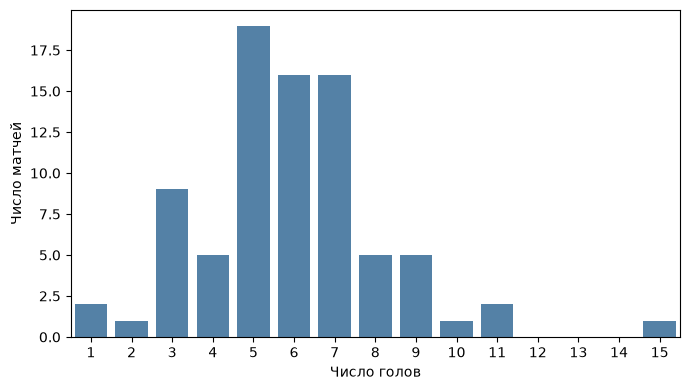

In [ ]:
#Задача 5

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
sns.countplot(x='Total Score', data=games,
              order=range(1, games['Total Score'].max() + 1),
              color='steelblue')
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.tight_layout()
plt.show()

Распределение одновершинное: чаще всего бывает 5 голов (19 матчей), 6 и 7 (по 16),
вместе это около 62% игр. Правый хвост длиннее левого, игра с 15 голами — выброс.
Игр с 1–2 голами мало (3 из 82). Типичный матч плей-офф заканчивался с суммарным счётом 5–7 шайб.

In [ ]:
# Задача 6

min_score = games['Total Score'].min()
max_score = games['Total Score'].max()

# все игры с минимальным и максимальным числом голов (их может быть несколько)
least = [gameInfo(i) for i in games[games['Total Score'] == min_score].index]
most = [gameInfo(i) for i in games[games['Total Score'] == max_score].index]

least

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [15]:
most

['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

Самые нерезультативные игры (1 гол): Montréal Canadiens – Tampa Bay Lightning (0:1) и
Philadelphia Flyers – Pittsburgh Penguins (1:0). Обе закончились в овертайме, то есть в
основное время счёт был 0:0.
Самая результативная игра (15 голов): Colorado Avalanche – Minnesota Wild (9:6), 3 мая 2026 г.
Она закончилась в основное время, то есть такой счёт набран без овертайма.

In [16]:
# Задача 7

away_cols = [f"Away Team's Player on the Ice #{i}" for i in range(1, 7)] + ["Away Team's Goalie"]
home_cols = [f"Home Team's Player on the Ice #{i}" for i in range(1, 7)] + ["Home Team's Goalie"]
player_cols = away_cols + home_cols

# для каждой игры собираем все значения этих столбцов в один ряд
# и считаем число разных игроков (nunique пропуски не считает)
games['Player Count'] = events.groupby('Game ID')[player_cols].apply(
    lambda d: pd.Series(d.values.ravel()).nunique())

top = games[games['Player Count'] == games['Player Count'].max()]
pd.DataFrame({'Game Info': [gameInfo(i) for i in top.index],
              'Player Count': top['Player Count']}, index=top.index)

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


Для каждой игры собраны все значения столбцов «Player on the Ice #1–#6» и «Goalie» обеих команд,
посчитано число различных игроков (пропуски не считаются). В большинстве игр (73 из 82) участвовало
38 игроков, в 8 играх — 39. Наибольшее число — 40 игроков — в игре Montréal Canadiens – Buffalo Sabres
(3:8, 16 мая 2026 г.), единственной с таким значением. Это та же игра, что и в примере из задания;
разница в одного игрока (41 в примере) объясняется тем, что в примере, по-видимому, пропуск считался за значение.

In [18]:
# Задача 8

import numpy as np

shot_types = ['shot-on-goal', 'goal', 'missed-shot']
shots = events[events['Play Type'].isin(shot_types)]

# кто бросает: хозяева или гости
is_home = shots['Team Making the Play'] == shots['Home Team']
# если хозяева защищают левые ворота, то они бросают в правые (X = 89), гости в левые (X = -89)
home_defends_left = shots["Home Team's Defending Side"] == 'left'
goal_x = np.where(is_home == home_defends_left, 89, -89)

x = shots['X Coordinate on the Ice Rink']
y = shots['Y Coordinate on the Ice Rink']

# расстояние до ближайшей точки створа (ворота шириной 6 футов, |y| <= 3)
dx = (x - goal_x).abs()
dy = np.maximum(y.abs() - 3, 0)        # 0, если бросок из зоны напротив ворот
events['Shot Length'] = np.sqrt(dx**2 + dy**2)   # у остальных событий будет NaN

events[events['Play Type'].isin(shot_types)][['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.206556
9,2025030111,missed-shot,12.000000
12,2025030111,missed-shot,29.410882
13,2025030111,shot-on-goal,62.169124
19,2025030111,missed-shot,52.924474
...,...,...,...
29695,2025030416,missed-shot,54.083269
29696,2025030416,missed-shot,5.099020
29704,2025030416,goal,46.238512
29706,2025030416,missed-shot,60.926185


Для каждого броска (shot-on-goal, goal, missed-shot) посчитано расстояние до ближайшей точки створа
ворот соперника. Сторону, в которую бросает команда, определяем по полю Home Team's Defending Side
и по тому, хозяева это или гости. Всего 7266 бросков. Среднее расстояние около 35 футов, медиана около 32,
75% бросков сделано с расстояния до 48 футов; максимум — 188 футов (бросок с противоположной половины площадки).

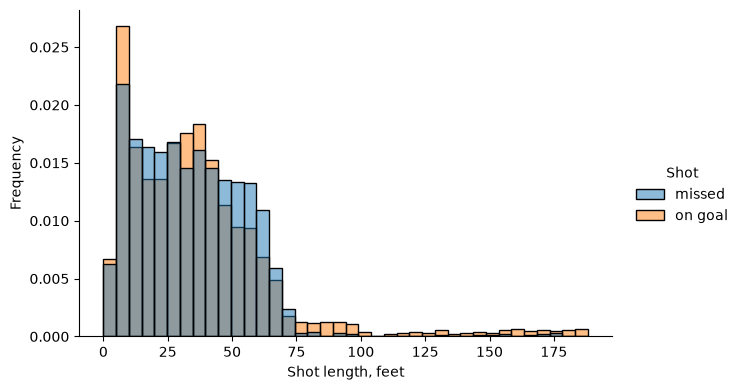

In [19]:
# Задача 9

import seaborn as sns
import matplotlib.pyplot as plt

shots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])].copy()
# точные броски: shot-on-goal и goal; неточные: missed-shot
shots['Shot'] = shots['Play Type'].map(lambda t: 'missed' if t == 'missed-shot' else 'on goal')

# stat='density' + common_norm=False: у каждой группы своя нормировка,
# поэтому группы разного размера (2643 и 4623 броска) можно сравнивать по форме
sns.displot(data=shots, x='Shot Length', hue='Shot',
            stat='density', common_norm=False, binwidth=5,
            height=4, aspect=1.6)
plt.xlabel('Shot length, feet')
plt.ylabel('Frequency')
plt.show()

Гистограммы расстояния построены отдельно для точных (shot-on-goal и goal) и неточных (missed-shot)
бросков, с нормировкой на размер каждой группы (stat='density', common_norm=False), так как группы
разного размера (2643 и 4623 броска).
Распределения похожи: основная масса бросков сделана с 10–50 футов, медианы почти равны (около 32 футов).
Значит, длина броска слабо различает точные и неточные броски.
У точных бросков заметно более длинный хвост: 4,8% бросков сделаны с расстояния более 89 футов
(со своей половины площадки) против 1,1% у неточных.
Объяснение: почти все такие голы забиты в конце 3-го периода, когда проигрывающая команда снимает вратаря,
и шайба попадает в пустые ворота. Кроме того, дальние броски, дошедшие до вратаря, засчитываются как броски в створ.

In [20]:
# Задача 10

# незаблокированные броски: в створ (shot-on-goal, goal) и мимо (missed-shot)
unblocked = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])].copy()
unblocked['On Goal'] = unblocked['Play Type'] != 'missed-shot'   # True для точных бросков

# среднее по булевому столбцу = доля точных бросков
numshots = (unblocked.groupby(['Game ID', 'Team Making the Play'])['On Goal']
            .mean().rename('Share of Shots on Goal'))
numshots

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625000
            Buffalo Sabres          0.678571
2025030112  Boston Bruins           0.613636
            Buffalo Sabres          0.636364
2025030113  Boston Bruins           0.694444
                                      ...   
2025030414  Vegas Golden Knights    0.583333
2025030415  Carolina Hurricanes     0.558140
            Vegas Golden Knights    0.510204
2025030416  Carolina Hurricanes     0.638889
            Vegas Golden Knights    0.594595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [21]:
numshots.describe()

count    164.000000
mean       0.639150
std        0.085000
min        0.352941
25%        0.582955
50%        0.638889
75%        0.688889
max        0.860465
Name: Share of Shots on Goal, dtype: float64

Для каждой команды в каждой игре посчитана доля бросков в створ (shot-on-goal и goal) среди всех
незаблокированных бросков (плюс missed-shot). Блокированные броски не учитываются.
В среднем доля равна 0,64, в большинстве игр она лежит между 0,58 и 0,69, то есть точность команд
в целом однородна. Крайние значения (0,35 и 0,86) — результат небольшого числа бросков в отдельной игре,
где случайные колебания заметны. Поэтому судить о точности команды надо по среднему за все матчи.

In [27]:
# Задача 11

# средняя по играм доля точных бросков для каждой команды
avgnumshots = numshots.groupby('Team Making the Play').mean()

avgnumshots.nlargest(5)

Team Making the Play
Edmonton Oilers        0.706232
Philadelphia Flyers    0.683668
Dallas Stars           0.670142
Minnesota Wild         0.656099
Colorado Avalanche     0.652559
Name: Share of Shots on Goal, dtype: float64

In [28]:
avgnumshots.nsmallest(5)

Team Making the Play
Pittsburgh Penguins    0.554046
Utah Mammoth           0.599298
Carolina Hurricanes    0.614844
Tampa Bay Lightning    0.625713
Buffalo Sabres         0.625838
Name: Share of Shots on Goal, dtype: float64

Доля точных бросков усреднена по матчам для каждой из 16 команд.
Лидеры: Edmonton Oilers (0,706), Philadelphia Flyers (0,684), Dallas Stars (0,670),
Minnesota Wild (0,656), Colorado Avalanche (0,653).
Аутсайдеры: Pittsburgh Penguins (0,554), Utah Mammoth (0,599), Carolina Hurricanes (0,615),
Tampa Bay Lightning (0,626), Buffalo Sabres (0,626).
Разброс между командами небольшой (от 0,55 до 0,71, среднее 0,64). Pittsburgh заметно отстаёт от остальных.
Но у многих команд из обоих списков сыграно только 6–7 матчей, поэтому случайность влияет на среднее
значительно, и ранжирование нужно воспринимать осторожно. Надёжнее выглядят результаты команд,
сыгравших больше игр (Carolina — 19 матчей, Colorado — 13).

In [29]:
# Задача 12

# все точные броски: shot-on-goal (отбитые/пойманные) и goal (голы)
on_target = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]

# число событий каждого типа у каждой команды в каждой игре
per_game = pd.crosstab([on_target['Game ID'], on_target['Team Making the Play']],
                       on_target['Play Type'])

per_game['Shot'] = per_game['shot-on-goal'] + per_game['goal']   # все броски в створ, включая голы
per_game['Goal'] = per_game['goal']

# среднее по играм для каждой команды
avgshots = per_game[['Shot', 'Goal']].groupby(level='Team Making the Play').mean()
avgshots

Play Type,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.666667,3.250000
Boston Bruins,25.166667,2.000000
Buffalo Sabres,30.461538,3.307692
Carolina Hurricanes,31.631579,3.473684
Colorado Avalanche,32.153846,3.384615
Dallas Stars,31.000000,2.500000
Edmonton Oilers,28.333333,3.500000
Los Angeles Kings,25.250000,1.250000
Minnesota Wild,28.727273,3.727273


Для каждой из 16 команд посчитано среднее за игру число бросков в створ (shot-on-goal плюс goal, так как гол
тоже бросок в створ) и среднее число голов. Расчёт идёт по играм, которые сыграла команда,
игры без голов учитываются как 0.
Больше всего бросков в створ у Colorado Avalanche (32,2), меньше всего у Montréal Canadiens (23,3).
Больше всего голов у Minnesota Wild (3,73), меньше всего у Los Angeles Kings и Ottawa Senators (по 1,25).
Число бросков и число голов совпадают не всегда: Ottawa делает 27,5 броска за игру, но забивает только 1,25 гола,
а Vegas при 26,5 броска забивает 3,45 гола.

In [31]:
# Задача 13

import numpy as np

r = avgshots['Shot'].corr(avgshots['Goal'])                  # коэффициент корреляции
slope, intercept = np.polyfit(avgshots['Shot'], avgshots['Goal'], 1)   # прямая регрессии

print(f"коэффициент корреляции r = {r:.3f}")
print(f"наклон = {slope:.3f}, r^2 = {r**2:.3f}")

коэффициент корреляции r = 0.521
наклон = 0.156, r^2 = 0.271


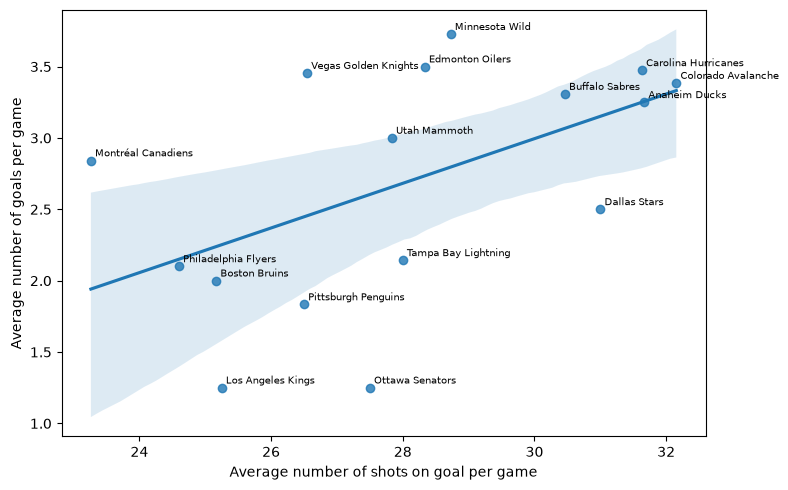

коэффициент корреляции r = 0.521
наклон = 0.156, r^2 = 0.271


In [32]:
# Задача 13

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# регрессионная диаграмма: каждая точка - одна команда
plt.figure(figsize=(8, 5))
sns.regplot(x='Shot', y='Goal', data=avgshots)

# подписи команд рядом с точками
for team, row in avgshots.iterrows():
    plt.annotate(team, (row['Shot'], row['Goal']), fontsize=7,
                 xytext=(3, 3), textcoords='offset points')

plt.xlabel('Average number of shots on goal per game')
plt.ylabel('Average number of goals per game')
plt.tight_layout()
plt.show()

# числовая оценка связи
r = avgshots['Shot'].corr(avgshots['Goal'])                       # коэффициент корреляции
slope, intercept = np.polyfit(avgshots['Shot'], avgshots['Goal'], 1)   # наклон прямой
print(f"коэффициент корреляции r = {r:.3f}")
print(f"наклон = {slope:.3f}, r^2 = {r**2:.3f}")

На диаграмме каждая точка — одна команда. Линия регрессии идёт вверх, коэффициент корреляции равен 0,52,
то есть между средним числом бросков в створ и средним числом голов есть положительная связь,
но умеренная: число бросков объясняет лишь около 27% разброса голов (r² = 0,27).
Наклон прямой 0,156: примерно +10 бросков в створ за игру соответствуют +1,6 гола за игру.
Ottawa Senators и Los Angeles Kings много бросают, но мало забивают (лежат ниже линии),
а Vegas Golden Knights и Minnesota Wild забивают больше, чем предсказывает число бросков (выше линии).
Оговорки: гол сам входит в число бросков в створ, что немного завышает связь;
точек всего 16, а у части команд сыграно только 6–7 матчей.
Вывод: связь заметна, но не сильная; одно число бросков хорошо не объясняет результативность.

In [33]:
# Задача 14

# все удары по воротам: в створ, голы, мимо и заблокированные
attempts = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot'])]

# число ударов в каждой игре
num_attempts = attempts.groupby('Game ID').size()

idxmax = num_attempts.idxmax()
print(num_attempts.max())
gameInfo(idxmax)

208


'Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)'

Больше всего ударов по воротам (с учётом промахов и заблокированных) было в игре
Carolina Hurricanes – Ottawa Senators (3:2, 2 овертайма, 20 апреля 2026 г.): 208 ударов.
Это значительно больше следующей по списку игры (169) и типичного значения (в среднем около 123 ударов за игру).
Главная причина — длительность: игра шла до второго овертайма, то есть заметно дольше 60 минут.

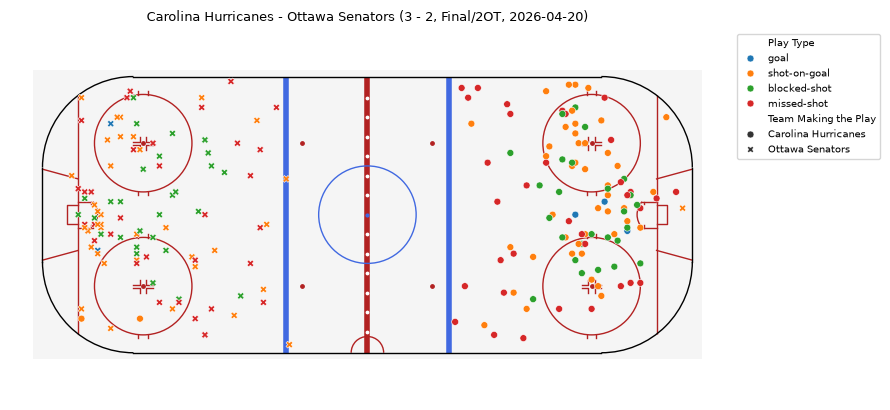

In [35]:
# Задача 15

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from rink import plot_rink

shot_types = ['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot']
game_shots = events[(events['Game ID'] == idxmax) & events['Play Type'].isin(shot_types)].copy()

# в нечётных периодах (1, 3, 5) меняем знак координат: (x, y) -> (-x, -y),
# тогда хозяева всегда бьют в правые ворота, а гости в левые
odd = game_shots['Period'] % 2 == 1
game_shots['x'] = np.where(odd, -game_shots['X Coordinate on the Ice Rink'],
                           game_shots['X Coordinate on the Ice Rink'])
game_shots['y'] = np.where(odd, -game_shots['Y Coordinate on the Ice Rink'],
                           game_shots['Y Coordinate on the Ice Rink'])

plt.figure(figsize=(9, 4.2))
plot_rink(False)
sns.scatterplot(data=game_shots, x='x', y='y',
                hue='Play Type',                      # исход удара - цветом
                style='Team Making the Play',         # команда - формой маркера
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                s=25)
plt.axis('equal')
plt.axis('off')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=7)
plt.title(gameInfo(idxmax), fontsize=9)
plt.tight_layout()
plt.show()

Построены все удары по воротам в игре Carolina Hurricanes – Ottawa Senators (3:2, 2 овертайма), найденной
в задаче 14. Координаты в нечётных периодах отражены, чтобы хозяева (Carolina) всегда бросали в правые ворота,
а гости (Ottawa) — в левые. Цвет точки показывает исход удара, форма маркера — команду.
Основная часть ударов приходится на зону нападения возле ворот соперника, особенно вблизи кругов вбрасывания
и перед воротами. Голы забиты в основном с короткой дистанции, заблокированные удары сосредоточены ближе к воротам,
а промахи разбросаны шире. Отдельные точки в нейтральной зоне — дальние броски.

In [36]:
# Задача 17

goals = events[events['Play Type'] == 'goal']

# голевые передачи записаны в двух полях: первый и второй ассистент
assists = pd.concat([goals['Player in the Event #2'],
                     goals['Player in the Event #3']])

# пропуски (голы без передач) убираем, считаем передачи каждого игрока
assists_count = assists.dropna().value_counts()
assists_count.head(10)

Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: count, dtype: int64

Голевые передачи считались по двум полям события goal: Player in the Event #2 (первая передача)
и #3 (вторая передача). Больше всех передач набрали Jack Eichel (20) и Mitch Marner (19), затем идут
Lane Hutson и Jackson Blake (по 13). Остальные в десятке (Nick Suzuki, Taylor Hall, Martin Necas, Shea Theodore,
Kirill Kaprizov, Quinn Hughes) набрали 11–12 передач. Лидеры заметно отрываются от остальных.
Нужно учитывать, что итоговое число зависит от числа сыгранных матчей: игроки команд, дошедших дальше,
набирают больше.

In [ ]:
# Задача 16

goals = events[events['Play Type'] == 'goal']

# автор гола записан в поле Player in the Event #1
scorers = goals['Player in the Event #1'].value_counts()

# keep='all' оставляет всех игроков, у которых столько же голов, сколько у десятого
scorers.nlargest(10, keep='all')

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Matt Boldy           7
Mark Stone           7
Name: count, dtype: int64

Голы посчитаны по полю Player in the Event #1 для событий goal. Больше всех голов забил Brett Howden (14),
затем Pavel Dorofeyev (12), Logan Stankoven (11) и Mitch Marner (10). На 7-м месте шесть игроков с 7 голами,
поэтому список «десяти лучших» расширен до 12 игроков (keep='all'), чтобы не выбирать случайно
между равными. Mitch Marner входит в верхнюю часть таблицы и по голам, и по передачам.

In [38]:
# Задача 18

# голы и передачи каждого игрока (из задач 16 и 17)
scoring = pd.DataFrame({'Goals': scorers, 'Assists': assists_count})
scoring = scoring.fillna(0).astype(int)      # нет голов или передач -> 0
scoring['Points'] = scoring['Goals'] + scoring['Assists']

# keep='all': не обрезаем список, если на 10-м месте ничья
top_points = scoring.loc[scoring['Points'].nlargest(10, keep='all').index]
top_points.sort_values(['Points', 'Goals'], ascending=False)

,Goals,Assists,Points
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Nikolaj Ehlers,8,10,18
Shea Theodore,6,12,18
Pavel Dorofeyev,12,4,16
Logan Stankoven,11,5,16
Nick Suzuki,4,12,16


Очки по системе «гол плюс пас» посчитаны как сумма голов (задача 16) и голевых передач (задача 17).
Игроки без голов или без передач получают 0 в соответствующем столбце.
Безусловный лидер — Mitch Marner (29 очков: 10 голов и 19 передач), второй — Jack Eichel (22 очка).
На 10-м месте ничья между четырьмя игроками с 16 очками, поэтому в список включены все 11 игроков.
Лидеры набирают очки по-разному: Eichel почти только передачами (20 передач и 2 гола),
Howden и Dorofeyev в основном голами (14 и 12 голов при 4 передачах).

In [39]:
# Задача 19

# броски в створ: shot-on-goal и goal (как в задаче 12)
on_target = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
shots_total = on_target['Player in the Event #1'].value_counts()

# число игр игрока: в скольких матчах он хотя бы раз был на льду (полевые игроки обеих команд)
field_cols = ([f"Away Team's Player on the Ice #{i}" for i in range(1, 7)] +
              [f"Home Team's Player on the Ice #{i}" for i in range(1, 7)])
on_ice = (events[['Game ID'] + field_cols]
          .melt(id_vars='Game ID', value_name='Player')
          .dropna(subset=['Player'])
          .drop_duplicates(['Game ID', 'Player']))
games_played = on_ice.groupby('Player').size()

players = pd.DataFrame({'Shots': shots_total})
players['Games'] = games_played.reindex(players.index)
players['Shots per Game'] = players['Shots'] / players['Games']

players.nlargest(10, 'Shots per Game')

,Shots,Games,Shots per Game
Player in the Event #1,,,
Jason Robertson,30,6,5.000000
Dylan Guenther,27,6,4.500000
Nikita Kucherov,31,7,4.428571
Matt Boldy,48,11,4.363636
Quinton Byfield,17,4,4.250000
Darren Raddysh,28,7,4.000000
Joel Eriksson Ek,24,6,4.000000
Alex Laferriere,15,4,3.750000
David Pastrnak,22,6,3.666667


Броски в створ (shot-on-goal и goal) посчитаны по полю Player in the Event #1. В число игр игрока включены
все матчи, в которых он хотя бы раз был на льду (среди полевых игроков). Больше всех бросков за игру наносит
Jason Robertson (5,0), далее Dylan Guenther (4,5), Nikita Kucherov (4,4) и Matt Boldy (4,4).
У некоторых игроков из списка сыграно всего 4 матча (Byfield, Laferriere), поэтому их средние нестабильны;
более надёжны результаты Boldy (11 матчей) и MacKinnon (13 матчей).

In [40]:
# Задача 20

# силовой приём: событие hit, исполнитель - в поле Player in the Event #1
hits_total = events[events['Play Type'] == 'hit']['Player in the Event #1'].value_counts()

hits = pd.DataFrame({'Hits': hits_total})
# число игр игрока (games_played из задачи 19: матчи, в которых игрок был на льду)
hits['Games'] = games_played.reindex(hits.index)
hits['Hits per Game'] = hits['Hits'] / hits['Games']

hits.nlargest(10, 'Hits per Game')

,Hits,Games,Hits per Game
Player in the Event #1,,,
Lawson Crouse,38,6,6.333333
Alex Turcotte,6,1,6.000000
Alexander Petrovic,6,1,6.000000
Yakov Trenin,51,9,5.666667
Dylan Cozens,22,4,5.500000
Vasily Podkolzin,32,6,5.333333
Ivan Barbashev,110,22,5.000000
Marcus Foligno,55,11,5.000000
Carl Grundstrom,15,3,5.000000


Силовые приёмы посчитаны по событиям hit (исполнитель — поле Player in the Event #1), число игр игрока —
как в задаче 19 (матчи, где он был на льду). Лидер — Lawson Crouse (6,3 приёма за игру).
В общем списке есть игроки, сыгравшие всего 1–3 матча (Turcotte, Petrovic, Grundstrom), их средние
ненадёжны. Если ограничиться игроками хотя бы с 5 матчами, лидерами остаются Crouse, Trenin (5,7),
Podkolzin (5,3), а наиболее показательны Barbashev (110 приёмов за 22 игры) и Cole Smith (100 за 22).

In [41]:
# Задача 21

import numpy as np

away_g, home_g = "Away Team's Goalie", "Home Team's Goalie"

# вратари в предыдущем событии той же игры
prev_away = events.groupby('Game ID')[away_g].shift(1)
prev_home = events.groupby('Game ID')[home_g].shift(1)

goals = events[events['Play Type'] == 'goal'].copy()
home_scored = goals['Team Making the Play'] == goals['Home Team']

# гол пропускает вратарь команды, которая НЕ забивала
goals['Goalie'] = np.where(home_scored, goals[away_g], goals[home_g])

# у голов, забитых в овертайме, поля игроков на льду пустые - берём вратаря из предыдущего события
prev_goalie = np.where(home_scored, prev_away[goals.index], prev_home[goals.index])
goals['Goalie'] = goals['Goalie'].where(goals['Goalie'].notna(), prev_goalie)

# сколько голов пропустил каждый вратарь в каждой игре
conceded = goals.dropna(subset=['Goalie']).groupby(['Game ID', 'Goalie']).size()

# все пары (игра, вратарь), в которых вратарь выходил на лёд, хотя бы на одно событие
appeared = pd.concat([events[['Game ID', away_g]].rename(columns={away_g: 'Goalie'}),
                      events[['Game ID', home_g]].rename(columns={home_g: 'Goalie'})]
                     ).dropna().drop_duplicates()
appeared = appeared.set_index(['Game ID', 'Goalie']).index

goals_against = conceded.reindex(appeared, fill_value=0)   # нет в conceded -> 0 голов
shutouts = goals_against[goals_against == 0]

sorted(shutouts.index.get_level_values('Goalie').unique())

['Andrei Vasilevskiy',
 'Brandon Bussi',
 'Dan Vladar',
 'Frederik Andersen',
 'Joonas Korpisalo',
 'Scott Wedgewood']

Для каждого гола определён вратарь пропустившей команды (по полям Away/Home Team's Goalie).
Голы, забитые в овертайме, в данных не содержат информации об игроках на льду, поэтому для них
вратарь взят из предыдущего события. Затем для каждой пары (игра, вратарь), в которой вратарь выходил на лёд,
посчитано число пропущенных голов; те пары, где оно равно 0, и есть «сухие» игры.
Таких вратарей шесть: Vasilevskiy, Bussi, Vladar, Andersen, Korpisalo, Wedgewood.
Korpisalo и Wedgewood не пропустили ни одного гола в играх, которые провели лишь частично
(на льду были около 24% и 64% времени событий). Если не заполнять вратаря для голов в овертайме,
в список ошибочно попали бы Silovs и Dobes — они на самом деле пропустили победные голы в овертайме.

In [42]:
# Задача 22

games['Home Win'] = games['Home Score'] > games['Away Score']   # True, если выиграли хозяева

print(games['Home Win'].sum(), 'из', len(games))
print(games['Home Win'].mean())

39 из 82
0.47560975609756095


Вопрос: выигрывают ли хозяева чаще гостей?
Хозяева выиграли 39 матчей из 82, то есть 47,6%. Это немного меньше половины, поэтому
преимущества домашней площадки в этих данных не видно. Оговорка: матчей всего 82,
так что такая разница (47,6% против 50%) вполне может быть случайной.